# MeshLens: from normal patterns to residual evidence

**Kumar Waibhav AKshat** - `kwa.waibhav@gmail.com`

This walkthrough executes the shipped trained autoencoder, verifies ONNX export agreement,
and reads the recorded held-out evaluation. It neither retrains a model nor tunes against
test labels. The task is image-level anomaly review on industrial grid material.
MVTec AD images and masks retain their CC BY-NC-SA 4.0 terms.


In [1]:
from pathlib import Path
import csv
import hashlib
import json
import sys
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import onnxruntime as ort

ROOT = Path.cwd()
if not (ROOT / 'artifacts/model.onnx').is_file():
    ROOT = ROOT.parent
assert (ROOT / 'artifacts/model.onnx').is_file(), 'Run from the project root or notebooks directory'
sys.path.insert(0, str(ROOT / 'src'))
from meshlens.core import preprocess_image, residual_score

metadata = json.loads((ROOT / 'artifacts/metadata.json').read_text())
evaluation = json.loads((ROOT / 'reports/metrics.json').read_text())
provenance = json.loads((ROOT / 'data/provenance.json').read_text())
selection = json.loads((ROOT / 'reports/selection.json').read_text())
print('Model:', metadata['model_version'])
print('Selected candidate:', selection['selected']['name'])
print('Current acquisition:', provenance['image_count'], 'images;', provenance['mask_count'], 'masks')
print('Roles:', provenance['split_counts'])


Model: meshlens-ae-b8d984eef4d4
Selected candidate: denoising
Current acquisition: 342 images; 57 masks
Roles: {'fit': 160, 'tune': 52, 'calibration': 52, 'test': 78}


## 1. Verify the experiment boundary

The source image is the split unit. Patches and synthetic versions never cross roles.
Fit, tune and calibration contain normal images only. Official test images remain outside
weight optimization, model/checkpoint choice, score-rule choice and threshold calibration.


In [2]:
manifest = ROOT / 'data/manifest.csv'
assert hashlib.sha256(manifest.read_bytes()).hexdigest() == provenance['manifest_sha256']
with manifest.open(newline='') as stream:
    rows = list(csv.DictReader(stream))
assert len({row['sha256'] for row in rows}) == len(rows)
assert all(row['label'] == '0' for row in rows if row['split'] != 'test')
for (role, label), count in sorted(Counter((row['split'], row['label']) for row in rows).items()):
    print(role, 'defect' if label == '1' else 'normal', count)
print('Current manifest hash, duplicate-image and normal-development contracts verified.')


calibration normal 52
fit normal 160
test normal 21
test defect 57
tune normal 52
Current manifest hash, duplicate-image and normal-development contracts verified.


## 2. Run the actual exported model

The tracked replay sample is already at model dimensions, so a clean source checkout can
inspect it without downloading raw training data. Input is RGB Float32 `[0,1]`, NCHW.
Still images resolve EXIF orientation and composite transparency over opaque white before
resizing. Source images are bounded to 32-4096 pixels per side and 16 megapixels. Opaque
benchmark inputs are unchanged by the alpha policy. Browser/Pillow resizing can differ for
arbitrary images. The model reconstructs RGB intensities; it does not output a defect-type label.


In [3]:
sample_path = sorted((ROOT / 'artifacts/samples').glob('*.png'))[0]
with Image.open(sample_path) as image:
    tensor = preprocess_image(image, int(metadata['image_size']))
options = ort.SessionOptions()
options.intra_op_num_threads = 1
session = ort.InferenceSession(str(ROOT / 'artifacts/model.onnx'), options,
                               providers=['CPUExecutionProvider'])
started = time.perf_counter()
reconstruction = session.run(None, {session.get_inputs()[0].name: tensor[None]})[0][0]
elapsed_ms = (time.perf_counter() - started) * 1000
fraction = float(metadata.get('score_top_fraction', selection['selected']['top_fraction']))
score, residual = residual_score(tensor, reconstruction, fraction)
threshold = float(metadata['threshold'])
print(json.dumps({'sample': sample_path.name, 'score': score, 'threshold': threshold,
                  'review_recommended': score > threshold, 'score_is_probability': False,
                  'inference_ms_this_run': round(elapsed_ms, 3)}, indent=2))
assert np.isfinite(score) and residual.shape == (256, 256)


{
  "sample": "bent-000.png",
  "score": 0.025862006785734217,
  "threshold": 0.02402208368407517,
  "review_recommended": true,
  "score_is_probability": false,
  "inference_ms_this_run": 22.643
}


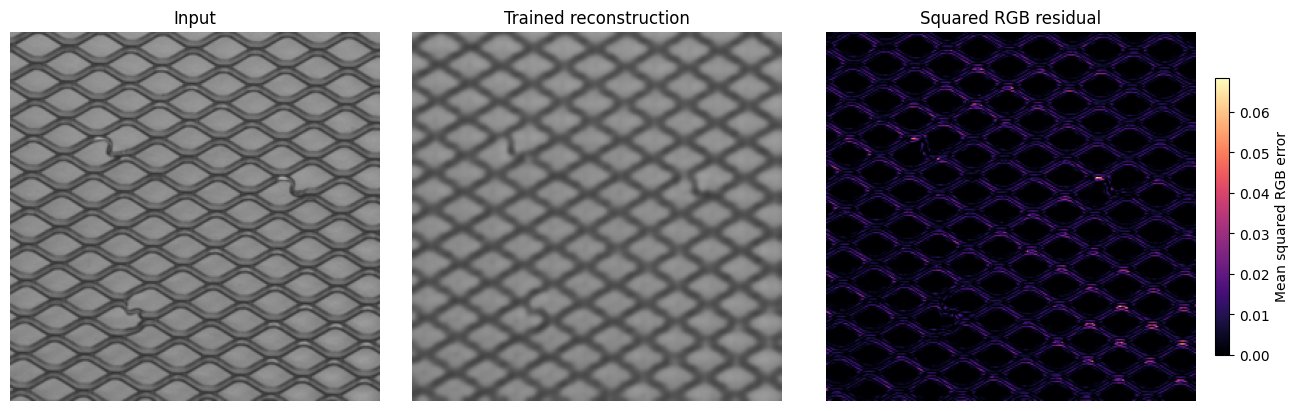

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
axes[0].imshow(tensor.transpose(1, 2, 0))
axes[0].set_title('Input')
axes[1].imshow(np.clip(reconstruction.transpose(1, 2, 0), 0, 1))
axes[1].set_title('Trained reconstruction')
heat = axes[2].imshow(residual, cmap='magma', vmin=0)
axes[2].set_title('Squared RGB residual')
for axis in axes:
    axis.axis('off')
fig.colorbar(heat, ax=axes[2], shrink=0.75, label='Mean squared RGB error')
plt.show()


## 3. Verify the trained checkpoint and exported graph agree

The same input tensor is reconstructed by both actual runtimes. This numerical check verifies
deployment agreement; it is separate from the held-out quality evaluation.


In [5]:
import torch
from meshlens.model import load_checkpoint

torch.set_num_threads(1)
model, config = load_checkpoint(ROOT / 'artifacts/checkpoint.pt')
with torch.inference_mode():
    native = model(torch.from_numpy(tensor[None])).numpy()[0]
maximum_error = float(np.max(np.abs(native - reconstruction)))
np.testing.assert_allclose(native, reconstruction, atol=1e-5, rtol=1e-4)
native_score, _ = residual_score(tensor, native, fraction)
print('Execution PyTorch version:', torch.__version__)
print('Execution ONNX Runtime version:', ort.__version__)
print('Maximum absolute tensor difference:', maximum_error)
print('Absolute score difference:', abs(native_score - score))
print('Trainable parameters:', sum(parameter.numel() for parameter in model.parameters()))
print('Checkpoint configuration:', config)


Execution PyTorch version: 2.14.1+cpu
Execution ONNX Runtime version: 1.23.2
Maximum absolute tensor difference: 2.086162567138672e-07
Absolute score difference: 1.252174561955366e-09
Trainable parameters: 25339
Checkpoint configuration: {'name': 'denoising', 'latent_channels': 8, 'noise_std': 0.035, 'seed': 43, 'best_tune_mse': 0.002289531985297799, 'epochs': 26, 'patches_per_epoch': 1280, 'batch_size': 64, 'patch_size': 64, 'image_size': 256, 'parameters': 25339, 'best_epoch': 26, 'top_fraction': 0.01}


## 4. Read current-run held-out results

AUROC/average precision summarize ranking. Precision, recall, F1 and actual confusion counts
describe the separate normal-calibrated threshold. Neither metric type establishes factory
reliability. High observed precision can coexist with many missed defects.


In [6]:
measured = evaluation['model']
print(f"Flagged {measured['true_positive']}/{evaluation['test_defect']} defects; "
      f"missed {measured['false_negative']}; "
      f"flagged {measured['false_positive']}/{evaluation['test_normal']} normal images.")
display(measured)
display(evaluation['baseline_patch_pca'])
if 'binomial_wilson_intervals_95' in evaluation:
    display(evaluation['binomial_wilson_intervals_95'])
print('Test loaded during selection:', selection['test_loaded_during_selection'])
print('Calibration loaded during selection:', selection['calibration_loaded_during_selection'])
print('Zero observed false alarms is not proof of zero population false-alarm risk.')


Flagged 11/57 defects; missed 46; flagged 0/21 normal images.
Test loaded during selection: False
Calibration loaded during selection: False
Zero observed false alarms is not proof of zero population false-alarm risk.


{'auroc': 0.7593984962406015,
 'average_precision': 0.9004571216615995,
 'precision': 1.0,
 'recall': 0.19298245614035087,
 'f1': 0.3235294117647059,
 'accuracy': 0.41025641025641024,
 'true_negative': 21,
 'false_positive': 0,
 'false_negative': 46,
 'true_positive': 11,
 'threshold': 0.02402208368407517,
 'samples': 78}

{'auroc': 0.7602339181286549,
 'average_precision': 0.8986582062410342,
 'precision': 1.0,
 'recall': 0.08771929824561403,
 'f1': 0.16129032258064516,
 'accuracy': 0.3333333333333333,
 'true_negative': 21,
 'false_positive': 0,
 'false_negative': 52,
 'true_positive': 5,
 'threshold': 0.01870466927605931,
 'samples': 78}

{'precision': {'lower': 0.7411670330319684, 'upper': 1.0},
 'recall': {'lower': 0.11132746980050533, 'upper': 0.3134069024776395},
 'specificity': {'lower': 0.8453609810751531, 'upper': 1.0},
 'false_alarm_rate': {'lower': 0.0, 'upper': 0.154639018924847}}

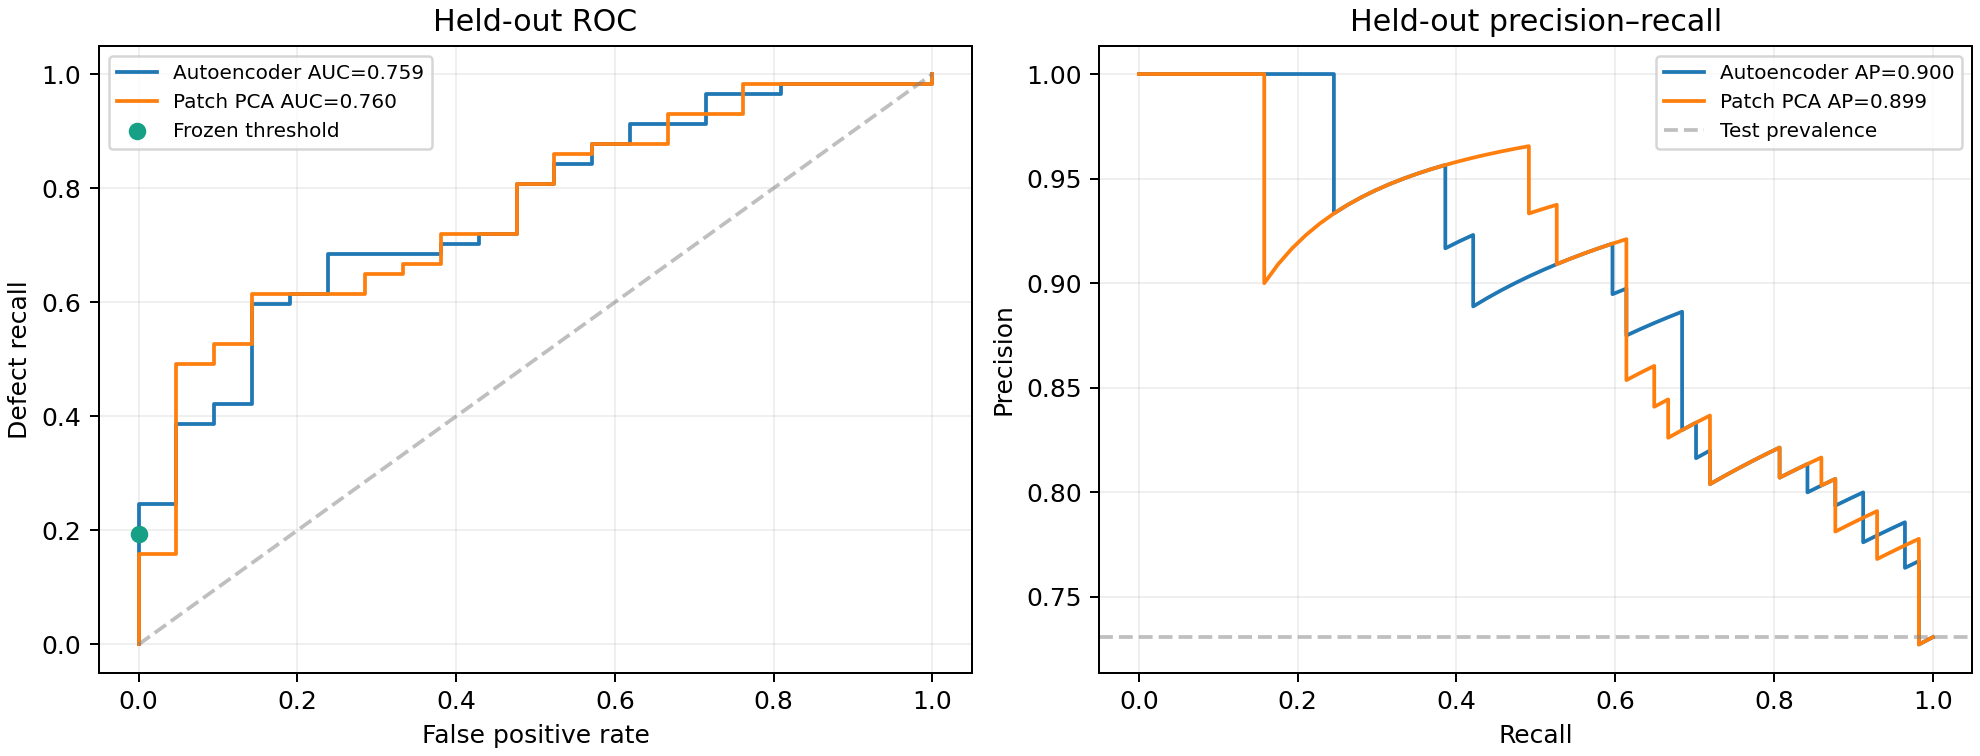

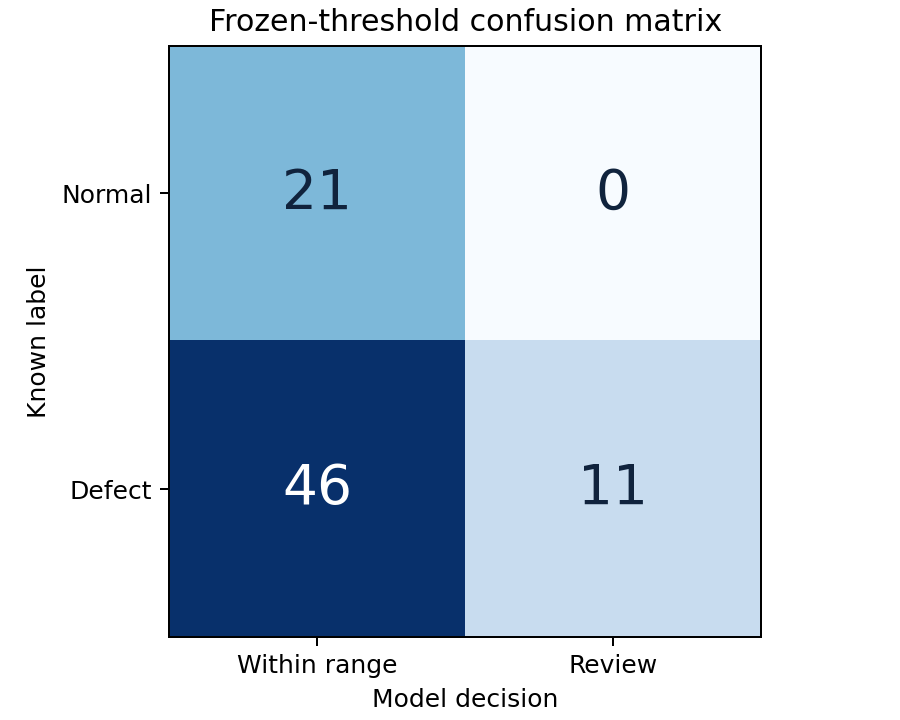

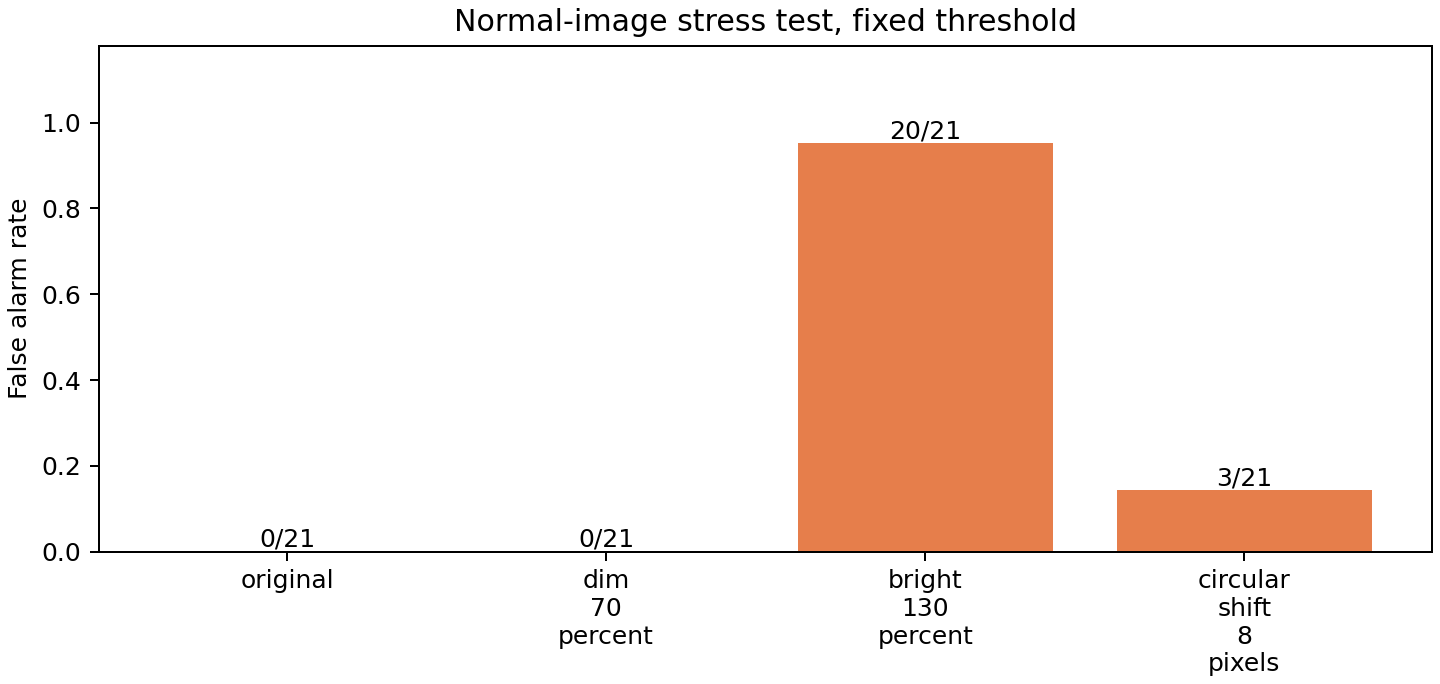

In [7]:
from IPython.display import Image as DisplayImage, display

for name in ['roc_pr.png', 'confusion_matrix.png', 'stress_test.png']:
    path = ROOT / 'reports/figures' / name
    assert path.is_file(), path
    display(DisplayImage(filename=str(path), width=850))


## 5. Interpretation and deployment

The static app runs the actual graph locally through ONNX Runtime Web. History is bounded and
browser local. Camera sampling needs user action and permission. Images are not uploaded to a
Python inference API. Reconstruction residuals support review rather than validated segmentation.

Camera inspection is serial and sampled, with a selectable delay after completed results;
it is not full-video-FPS processing. Model-call time is separate from end-to-end latency.
Physical camera hardware, line speed and long-duration operation have not been validated.

Lighting, scale, pose, blur and unfamiliar material can alter scores. The curated benchmark is
small and recall is limited; the checkpoint does not qualify automatic material acceptance or
rejection. See the model/data cards, project audit and workflow guide for exact release scope.

To rebuild after installing the pinned environment, run acquisition, training, evaluation and
export scripts in order. `npm ci` and `npm run build` produce the static web output. Completed
candidates are reused by default; fresh optimization uses a separate copy as documented in
the workflow guide. This walkthrough itself does not retrain or retune the network.
